## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

OUT = "notebooks/Outputs/Closed vs GD"
os.makedirs(OUT, exist_ok=True)

## Inputs

In [2]:
train_data = np.loadtxt("data/poly_train.csv", delimiter=",", skiprows=1)
test_data = np.loadtxt("data/poly_test.csv", delimiter=",", skiprows=1)

x, t = train_data[:, 0], train_data[:, 1]
x_test, t_test = test_data[:, 0], test_data[:, 1]

## Design matrix and Prediction

In [3]:
def design_matrix(x, d):
    return np.column_stack([x**i for i in range(d + 1)])

def prediction(x,w,d):
    Phi = design_matrix(x,d)

    y_pred = Phi @ w

    loss = 0
    for i in range(10):
        loss += (y_pred[i]-t[i])**2
    loss/=2

    return [y_pred,loss]

# 1. Closed Form

solve w = arg min(w) ||y_pred - t||^2


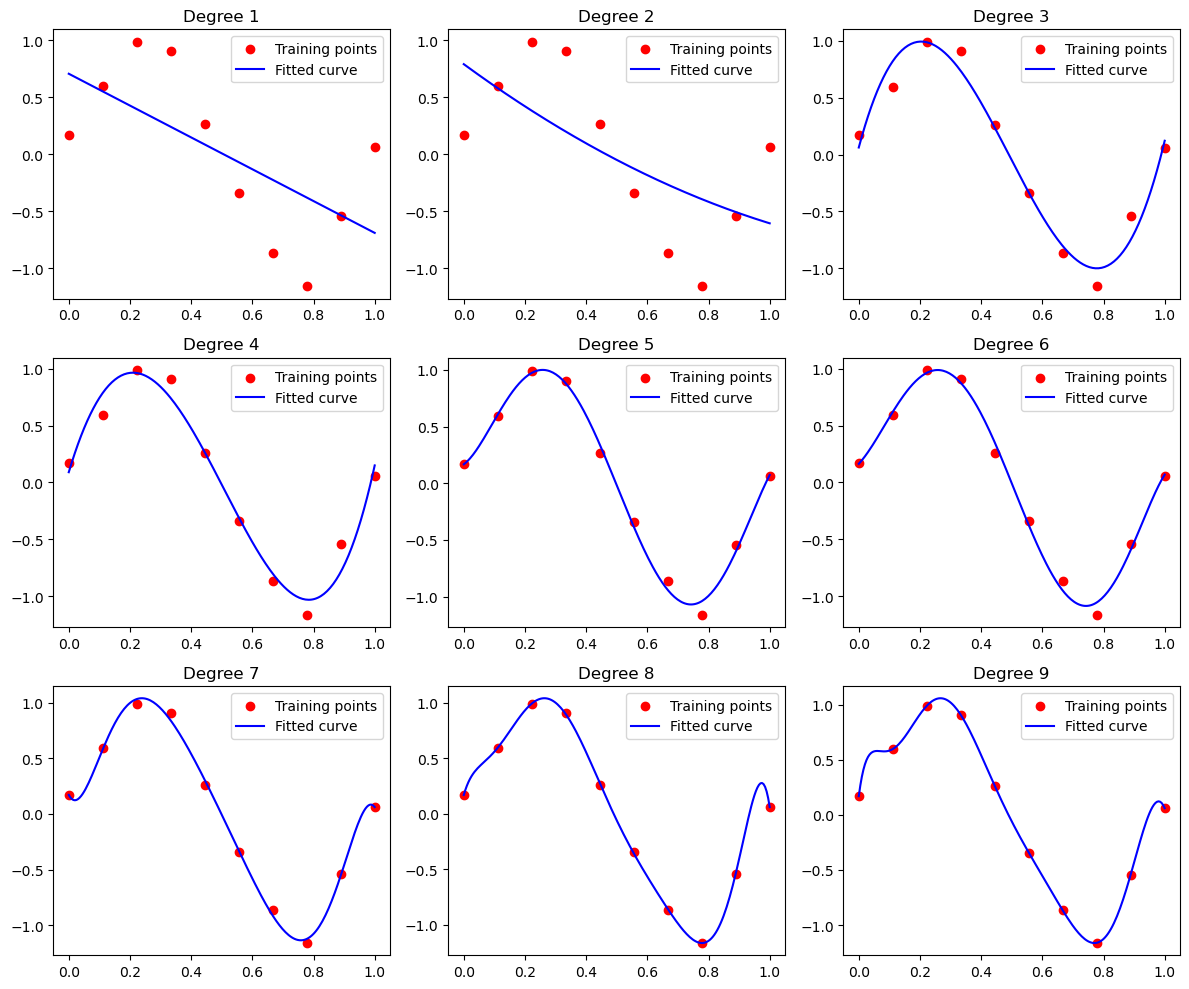

In [5]:
x_dense = np.linspace(0, 1, 200)

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for d, ax in zip(range(1, 10), axes.flatten()):
    Phi = design_matrix(x, d)
    w = np.linalg.lstsq(Phi, t, rcond=None)[0]

    y_pred, _ = prediction(x_dense, w, d)

    ax.scatter(x, t, color="red", label="Training points")
    ax.plot(x_dense, y_pred, color="blue", label="Fitted curve")
    ax.set_title(f"Degree {d}")
    ax.legend()

plt.tight_layout()
plt.savefig(f"{OUT}/polynomial_fits.png")
plt.show()


# 2. Gradient Descent

In [6]:
Phi = design_matrix(x, 9)
Q, R = np.linalg.qr(Phi, mode="reduced")

def loss(w, t):
    return 0.5 * np.sum((Q @ w - t)**2)

def gradient(w, t):
    return Q.T @ (Q @ w - t)

def batch_gd(w0, eta, t, epochs):
    losses = []

    w = w0.copy()
    for _ in range(epochs):
        grad = gradient(w, t)
        w = w - eta * grad
        current_loss = loss(w, t)
        losses.append(current_loss)

    return w, losses

def stochastic_gd(w0, eta, t, epochs):
    losses = []

    w = w0.copy()
    for _ in range(epochs):
        for i in np.random.permutation(len(t)):
            grad = Q[i] * (Q[i] @ w - t[i])
            w = w - eta * grad

        current_loss = loss(w, t)
        losses.append(current_loss)

    return w, losses

def minibatch_gd(w0, eta, t, epochs, batch_size=3):
    losses = []
    N = len(t)

    w = w0.copy()
    for _ in range(epochs):
        order = np.random.permutation(N)

        for start in range(0, N, batch_size):
            idx = order[start:start + batch_size]
            grad = Q[idx].T @ (Q[idx] @ w - t[idx]) / len(idx)
            w = w - eta * grad

        losses.append(loss(w, t))

    return w, losses

eta = 0.1
epochs = 2000

w0 = np.zeros(len(t))
alpha_batch, losses_batch = batch_gd(w0, eta, t, epochs)
alpha_sto, losses_sto = stochastic_gd(w0, eta, t, epochs)
alpha_mb, losses_mb = minibatch_gd(w0, eta, t, epochs)

w_batch = np.linalg.solve(R, alpha_batch)
w_sto = np.linalg.solve(R, alpha_sto)
w_mb = np.linalg.solve(R, alpha_mb)

## Loss Curves

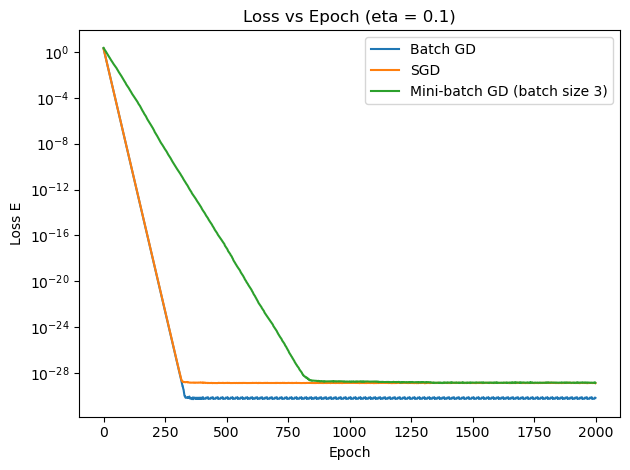

In [7]:
plt.plot(losses_batch, label="Batch GD")
plt.plot(losses_sto, label="SGD")
plt.plot(losses_mb, label="Mini-batch GD (batch size 3)")

plt.yscale("log") # log scale y-axis
plt.xlabel("Epoch")
plt.ylabel("Loss E")
plt.title("Loss vs Epoch (eta = 0.1)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/loss_curves.png")
plt.show()

##  Learning-rate study

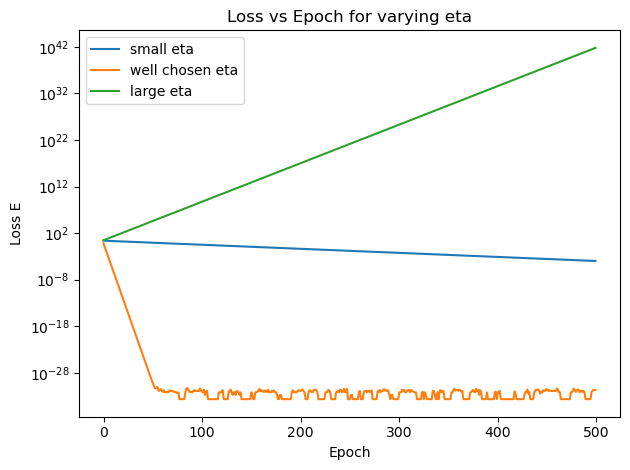

In [9]:
epochs = 500

alpha_batch_small, losses_batch_small = batch_gd(w0, 0.01, t, epochs)
w_batch_small = np.linalg.solve(R, alpha_batch_small)
alpha_batch_good, losses_batch_good = batch_gd(w0, 0.5, t, epochs)
w_batch_good = np.linalg.solve(R, alpha_batch_good)
alpha_batch_large, losses_batch_large = batch_gd(w0, 2.1, t, epochs)
w_batch_large = np.linalg.solve(R, alpha_batch_large)

plt.plot(losses_batch_small, label="small eta")
plt.plot(losses_batch_good, label="well chosen eta")
plt.plot(losses_batch_large, label="large eta")

plt.yscale("log") # log scale y-axis
plt.xlabel("Epoch")
plt.ylabel("Loss E")
plt.title("Loss vs Epoch for varying eta")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/learning_rate_study.png")
plt.show()

## Verification

In [10]:
eta = 0.1
epochs = 2000

# Closed-form solution in original polynomial space
w_closed = np.linalg.lstsq(Phi, t, rcond=None)[0]

# Run all three variants from alpha = 0
alpha_batch, _ = batch_gd(np.zeros(10), eta, t, epochs)
alpha_sto, _ = stochastic_gd(np.zeros(10), eta, t, epochs)
alpha_mb, _ = minibatch_gd(np.zeros(10), eta, t, epochs)

# Recover original-space weights: w = R^(-1) alpha
w_batch = np.linalg.solve(R, alpha_batch)
w_sto = np.linalg.solve(R, alpha_sto)
w_mb = np.linalg.solve(R, alpha_mb)

# Calculate absolute and relative errors
for name, w_gd in [
    ("Batch GD", w_batch),
    ("SGD", w_sto),
    ("Mini-batch GD", w_mb)
]:
    abs_error = np.linalg.norm(w_gd - w_closed)
    rel_error = abs_error / np.linalg.norm(w_closed)

    print(f"{name}:")
    print(f"  Absolute error = {abs_error:.6e}")
    print(f"  Relative error = {rel_error:.6e}")

Batch GD:
  Absolute error = 1.597123e-05
  Relative error = 1.462857e-10
SGD:
  Absolute error = 1.597176e-05
  Relative error = 1.462905e-10
Mini-batch GD:
  Absolute error = 1.597171e-05
  Relative error = 1.462900e-10
